In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [7]:
seller_performance = pd.read_csv("../results/02_seller_performance.csv")

In [11]:
print(seller_performance.shape)
seller_performance.head()

(2965, 4)


,seller_id,avg_score,revenue,revenue_tiers
0,ee27a8f15b1dded4d213a468ba4eb391,5.0,6726.66,high_revenue
1,2addf05f476d0637864454e93ba673d5,5.0,4877.64,high_revenue
2,a63bfbaa882c8f4542891b4e2246cc7f,5.0,5925.99,high_revenue
3,ff4ea69c2a729e83e63c7579e4ef8170,5.0,6527.82,high_revenue
4,e3b4998c7a498169dc7bce44e6bb6277,5.0,6929.31,high_revenue


In [29]:
tier_column_avg_score = seller_performance.groupby("revenue_tiers")["avg_score"].mean()
tier_column_avg_score.head()

revenue_tiers
high_revenue      4.130864
low_revenue       4.160812
medium_revenue    4.206667
Name: avg_score, dtype: float64

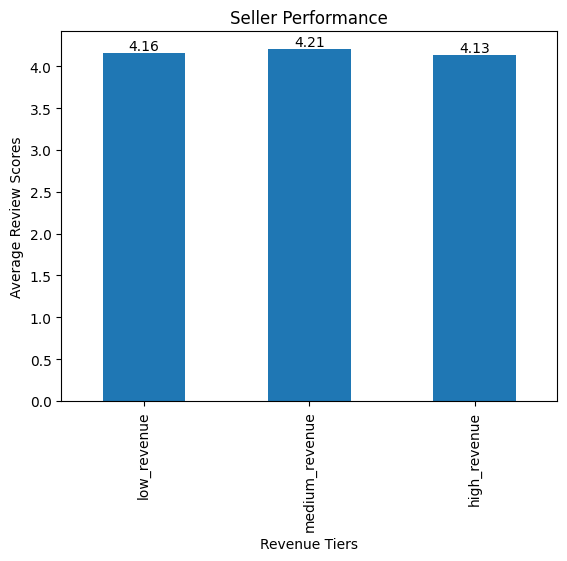

In [42]:
tier_column_avg_score = tier_column_avg_score.reindex(["low_revenue", "medium_revenue", "high_revenue"])
bar = tier_column_avg_score.plot(kind="bar")
bar.bar_label(bar.containers[0], fmt="%.2f") 
plt.title("Seller Performance")
plt.ylabel("Average Review Scores")
plt.xlabel("Revenue Tiers")
plt.show()


**Findings**

- The average review scores of the sellers in the three revenue tiers (low, medium and high revenue) all sit at 4 and above. 4.21 is the highest average review score from medium-revenue sellers. It was followed by 4.16 by low-revenue sellers, and lastly 4.13 by the high-revenue sellers. 
- The range is tight: only 0.08 between the highest and lowest which means they have almost the same average review scores and revenue tier barely affects review score. 
- An earlier version of the query counted a review once for every item in the order; after correcting this, all three averages rose, which suggests that multi-item orders score lower.
- Note that each seller counts equally in the tier average, so a seller with only one review has the same weight as a seller with hundreds of reviews.